#  Analyse univariée

##  Contexte et objectifs

L'analyse univariée consiste à étudier individuellement chaque variable explicative du dataset MetroPT-3.

Elle permet de comprendre les distributions, les caractéristiques statistiques, la dispersion et les valeurs extrêmes potentielles.

Cette étape constitue une base essentielle pour les analyses bivariées, multivariées et les futures étapes de feature engineering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import yaml

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [5]:
with open("../config.yaml", "r", encoding="utf-8") as fichier:
    config = yaml.safe_load(fichier)

# Chargement du dataset
chemin_dataset = (
    Path("../")
    / config["data"]["processed_path"]
    / config["data"]["processed_dataset_name"]
)

df = pd.read_csv(chemin_dataset)

# Conversion des colonnes
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["event_id"] = df["event_id"].astype("Int64")

print("Dataset chargé avec succès.")
print("Dimensions :", df.shape)

Dataset chargé avec succès.
Dimensions : (1516948, 19)


In [10]:
# Récupération du dossier de sauvegarde des figures
DOSSIER_FIGURES = Path("../") / config["artefacts"]["figures_dir"]

# Création du dossier s'il n'existe pas
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

print("Dossier des figures :", DOSSIER_FIGURES.resolve())

Dossier des figures : C:\Users\ngueb\Desktop\Prédictive_maintenance_MLOPS\reports\figures


In [6]:
variables_numeriques = config["features"]["numeric"]
variables_digitales = config["features"]["categorical"]

print("Variables numériques :", len(variables_numeriques))
print(variables_numeriques)

print("\nVariables digitales :", len(variables_digitales))
print(variables_digitales)

Variables numériques : 7
['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']

Variables digitales : 8
['COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


In [7]:
# Vérification des colonnes attendues
assert set(variables_numeriques).issubset(df.columns)
assert set(variables_digitales).issubset(df.columns)

# Vérification des valeurs manquantes
print("Valeurs manquantes dans les variables numériques :")
display(df[variables_numeriques].isna().sum())

print("Valeurs manquantes dans les variables digitales :")
display(df[variables_digitales].isna().sum())

print("\nTypes des variables :")
display(df[variables_numeriques + variables_digitales].dtypes)

Valeurs manquantes dans les variables numériques :


TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
dtype: int64

Valeurs manquantes dans les variables digitales :


COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64


Types des variables :


TP2                float64
TP3                float64
H1                 float64
DV_pressure        float64
Reservoirs         float64
Oil_temperature    float64
Motor_current      float64
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object

## Analyse statistique des variables numériques

Cette section étudie les sept variables analogiques du dataset.

L'objectif est de mesurer leur tendance centrale, leur dispersion et leur étendue à travers les principaux indicateurs statistiques.

Les variables étudiées sont :

- TP2
- TP3
- H1
- DV_pressure
- Reservoirs
- Oil_temperature
- Motor_current

In [8]:
# Statistiques descriptives des variables numériques
statistiques_numeriques = df[variables_numeriques].describe().T

# Ajout de l'écart interquartile
statistiques_numeriques["IQR"] = (
    statistiques_numeriques["75%"]
    - statistiques_numeriques["25%"]
)

# Ajout de l'asymétrie
statistiques_numeriques["Skewness"] = (
    df[variables_numeriques].skew()
)

# Ajout de l'aplatissement
statistiques_numeriques["Kurtosis"] = (
    df[variables_numeriques].kurtosis()
)

display(statistiques_numeriques)

,count,mean,std,min,25%,50%,75%,max,IQR,Skewness,Kurtosis
TP2,1516948.0000,1.3678,3.2509,-0.0320,-0.0140,-0.0120,-0.0100,10.6760,0.0040,1.9863,2.0607
TP3,1516948.0000,8.9846,0.6391,0.7300,8.4920,8.9600,9.4920,10.3020,1.0000,-0.8773,7.3953
H1,1516948.0000,7.5682,3.3332,-0.0360,8.2540,8.7840,9.3740,10.2880,1.1200,-1.7650,1.2962
DV_pressure,1516948.0000,0.0560,0.3824,-0.0320,-0.0220,-0.0200,-0.0180,9.8440,0.0040,5.7206,38.7150
Reservoirs,1516948.0000,8.9852,0.6383,0.7120,8.4940,8.9600,9.4920,10.3000,0.9980,-0.8862,7.4822
Oil_temperature,1516948.0000,62.6442,6.5163,15.4000,57.7750,62.7000,67.2500,89.0500,9.4750,-0.0458,-0.0578
Motor_current,1516948.0000,2.0502,2.3021,0.0200,0.0400,0.0450,3.8075,9.2950,3.7675,0.4486,-1.4508


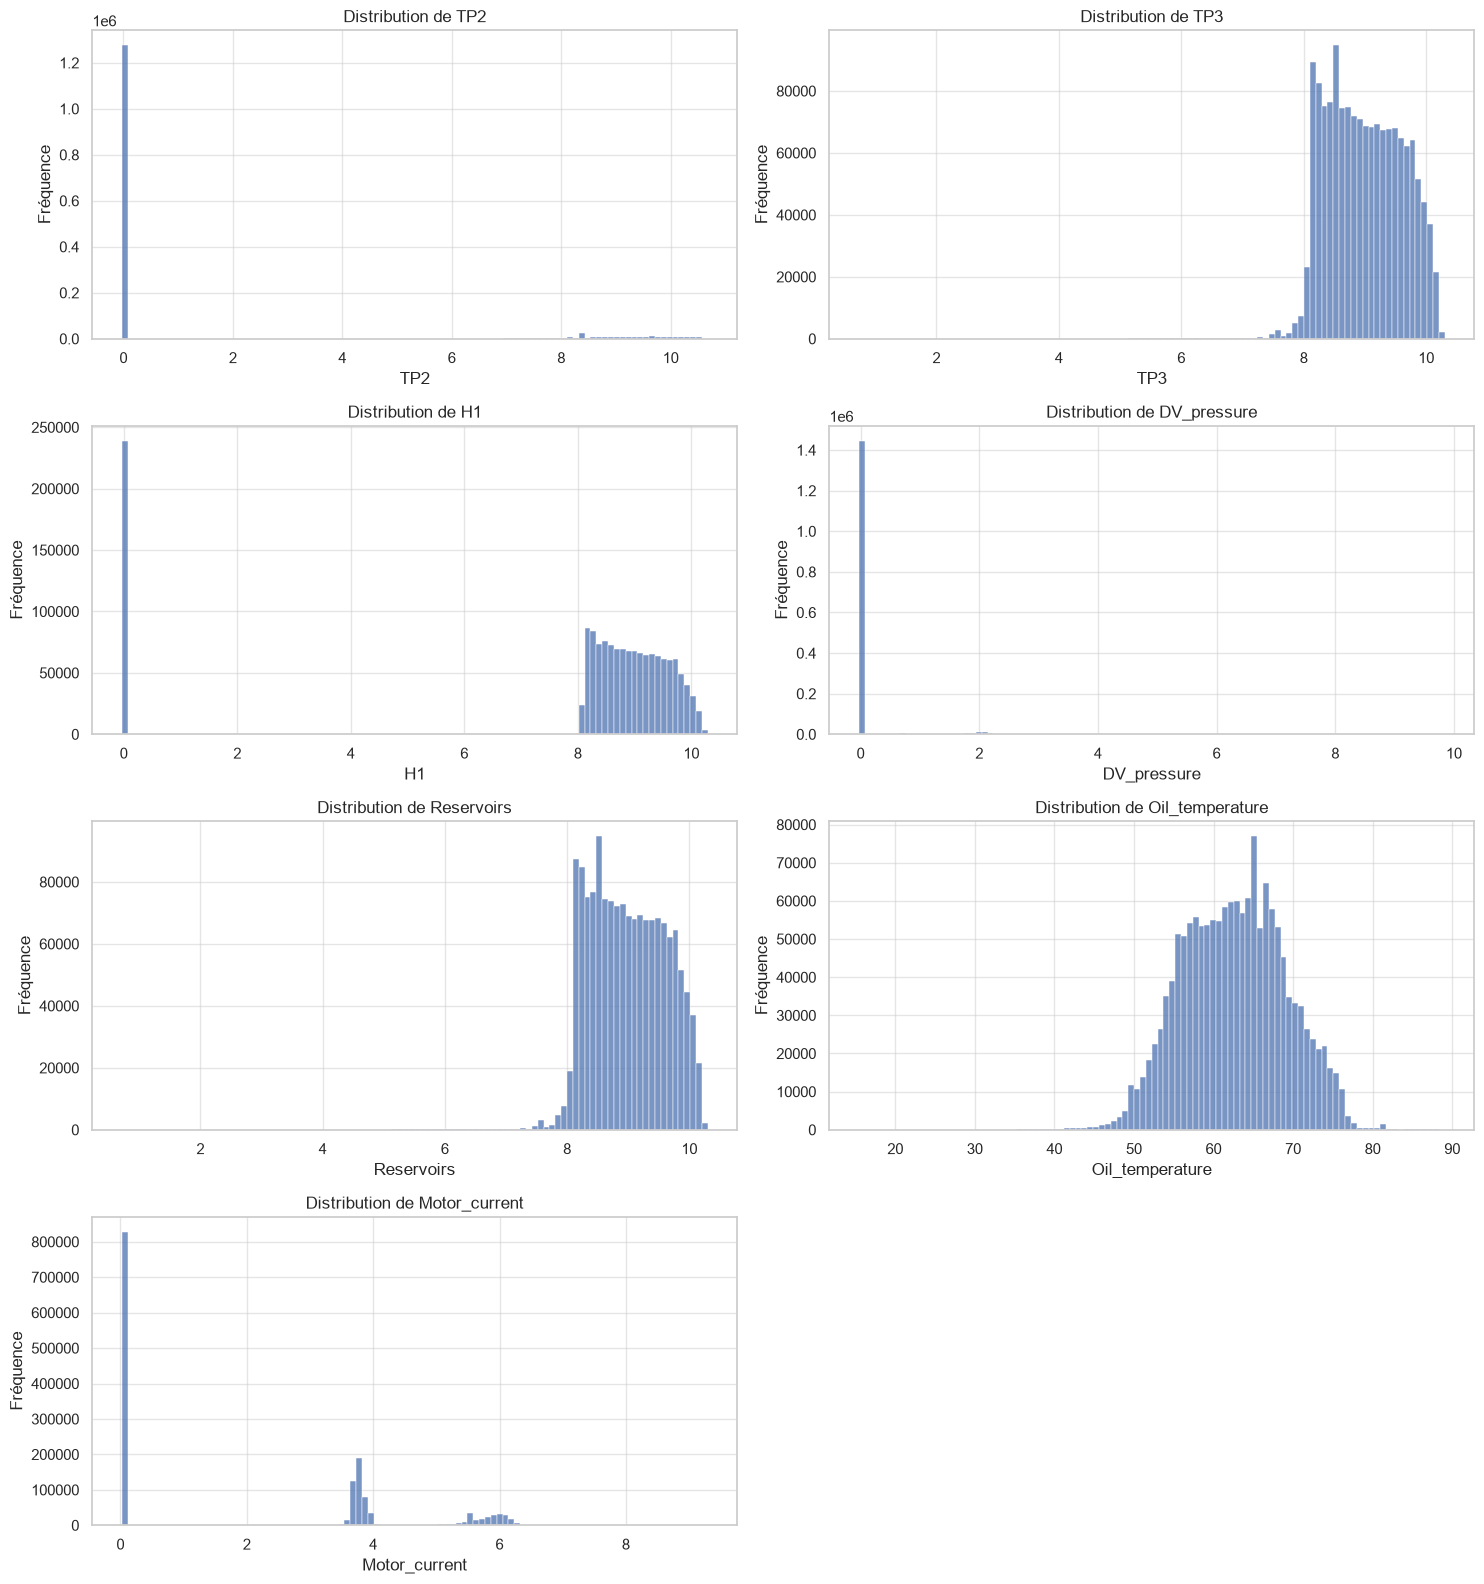

Figure enregistrée : ..\reports\figures\04_numeric_distributions.png


In [11]:
# Histogrammes des variables numériques
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 16)
)

axes = axes.flatten()

for i, variable in enumerate(variables_numeriques):

    sns.histplot(
        data=df,
        x=variable,
        bins=100,
        kde=False,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution de {variable}")
    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Fréquence")

# Suppression du dernier graphique inutilisé
fig.delaxes(axes[-1])

plt.tight_layout()

# Sauvegarde
chemin_figure = DOSSIER_FIGURES / "04_numeric_distributions.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

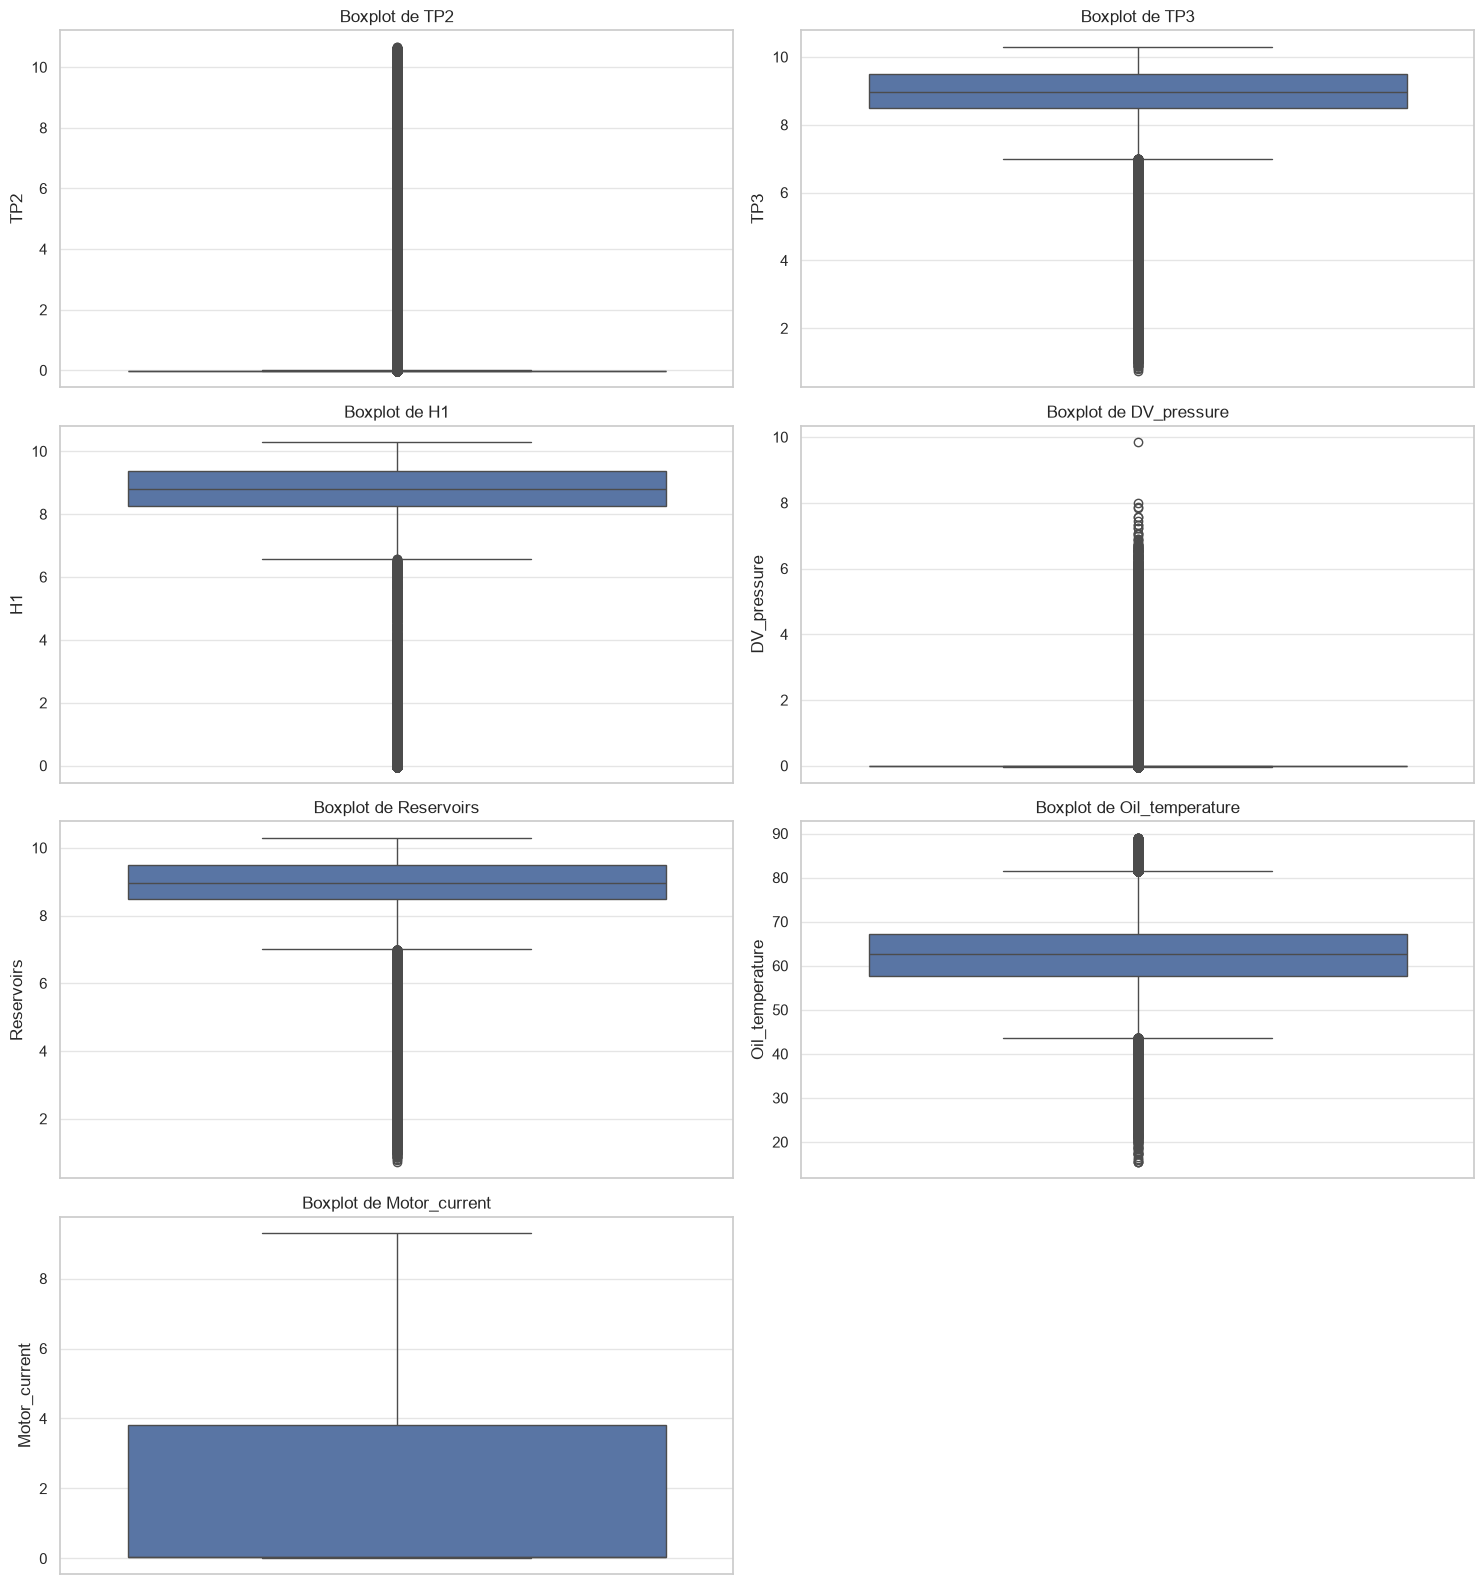

Figure enregistrée : ..\reports\figures\04_numeric_boxplots.png


In [12]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 16)
)

axes = axes.flatten()

for i, variable in enumerate(variables_numeriques):

    sns.boxplot(
        data=df,
        y=variable,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot de {variable}")
    axes[i].set_ylabel(variable)

fig.delaxes(axes[-1])

plt.tight_layout()

# Sauvegarde
chemin_figure = DOSSIER_FIGURES / "04_numeric_boxplots.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

In [13]:
resultats_outliers = []

for variable in variables_numeriques:

    q1 = df[variable].quantile(0.25)
    q3 = df[variable].quantile(0.75)

    iqr = q3 - q1

    borne_inf = q1 - 1.5 * iqr
    borne_sup = q3 + 1.5 * iqr

    masque_outliers = (
        (df[variable] < borne_inf)
        | (df[variable] > borne_sup)
    )

    nombre_outliers = masque_outliers.sum()

    resultats_outliers.append({
        "Variable": variable,
        "Borne_inf": borne_inf,
        "Borne_sup": borne_sup,
        "Nombre_outliers": nombre_outliers,
        "Pourcentage_outliers": (
            nombre_outliers / len(df) * 100
        )
    })

df_outliers = pd.DataFrame(resultats_outliers)

display(df_outliers)

,Variable,Borne_inf,Borne_sup,Nombre_outliers,Pourcentage_outliers
0,TP2,-0.0200,-0.0040,269592,17.7720
1,TP3,6.9920,10.9920,4518,0.2978
2,H1,6.5740,11.0540,241327,15.9087
3,DV_pressure,-0.0280,-0.0120,113111,7.4565
4,Reservoirs,6.9970,10.9890,4526,0.2984
5,Oil_temperature,43.5625,81.4625,5194,0.3424
6,Motor_current,-5.6113,9.4588,0,0.0000


### Interprétation des valeurs atypiques

L'application de la règle de Tukey met en évidence des proportions différentes de valeurs atypiques selon les variables.

Les proportions les plus importantes concernent TP2 (17,77 %), H1 (15,91 %) et DV_pressure (7,46 %).

À l'inverse, TP3, Reservoirs et Oil_temperature présentent moins de 0,35 % de valeurs atypiques. Aucune observation atypique n'est détectée pour Motor_current selon cette méthode.

Ces résultats doivent être interprétés avec prudence. Dans un environnement industriel, les valeurs éloignées de la distribution centrale peuvent correspondre à des régimes de fonctionnement particuliers ou à des phénomènes physiques réels.

Aucune observation ne sera supprimée à ce stade. Une investigation complémentaire sera nécessaire avant toute décision de traitement.

##  Analyse des variables digitales

Cette section étudie les huit variables digitales du dataset.

L'objectif est d'identifier les différentes valeurs observées, de vérifier leur cardinalité et de mesurer la fréquence de chaque état.

Bien que ces variables soient stockées au format float64, leur nature statistique doit être déterminée à partir des valeurs réellement présentes.

In [14]:
# Identification des valeurs distinctes
for variable in variables_digitales:

    valeurs = sorted(df[variable].dropna().unique())

    print(f"\nVariable : {variable}")
    print("Nombre de valeurs distinctes :", len(valeurs))
    print("Valeurs observées :", valeurs)


Variable : COMP
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]

Variable : DV_eletric
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]

Variable : Towers
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]

Variable : MPG
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]

Variable : LPS
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]

Variable : Pressure_switch
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]

Variable : Oil_level
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]

Variable : Caudal_impulses
Nombre de valeurs distinctes : 2
Valeurs observées : [np.float64(0.0), np.float64(1.0)]


In [15]:
resultats_digitales = []

for variable in variables_digitales:

    effectifs = df[variable].value_counts().sort_index()
    frequences = df[variable].value_counts(normalize=True).sort_index() * 100

    resultats_digitales.append({
        "Variable": variable,
        "Effectif_0": effectifs.get(0.0, 0),
        "Pourcentage_0": frequences.get(0.0, 0),
        "Effectif_1": effectifs.get(1.0, 0),
        "Pourcentage_1": frequences.get(1.0, 0)
    })

df_frequences_digitales = pd.DataFrame(resultats_digitales)

display(df_frequences_digitales)

,Variable,Effectif_0,Pourcentage_0,Effectif_1,Pourcentage_1
0,COMP,247328,16.3043,1269620,83.6957
1,DV_eletric,1273310,83.9389,243638,16.0611
2,Towers,121586,8.0152,1395362,91.9848
3,MPG,253840,16.7336,1263108,83.2664
4,LPS,1511760,99.6580,5188,0.3420
5,Pressure_switch,12990,0.8563,1503958,99.1437
6,Oil_level,145391,9.5844,1371557,90.4156
7,Caudal_impulses,95406,6.2893,1421542,93.7107


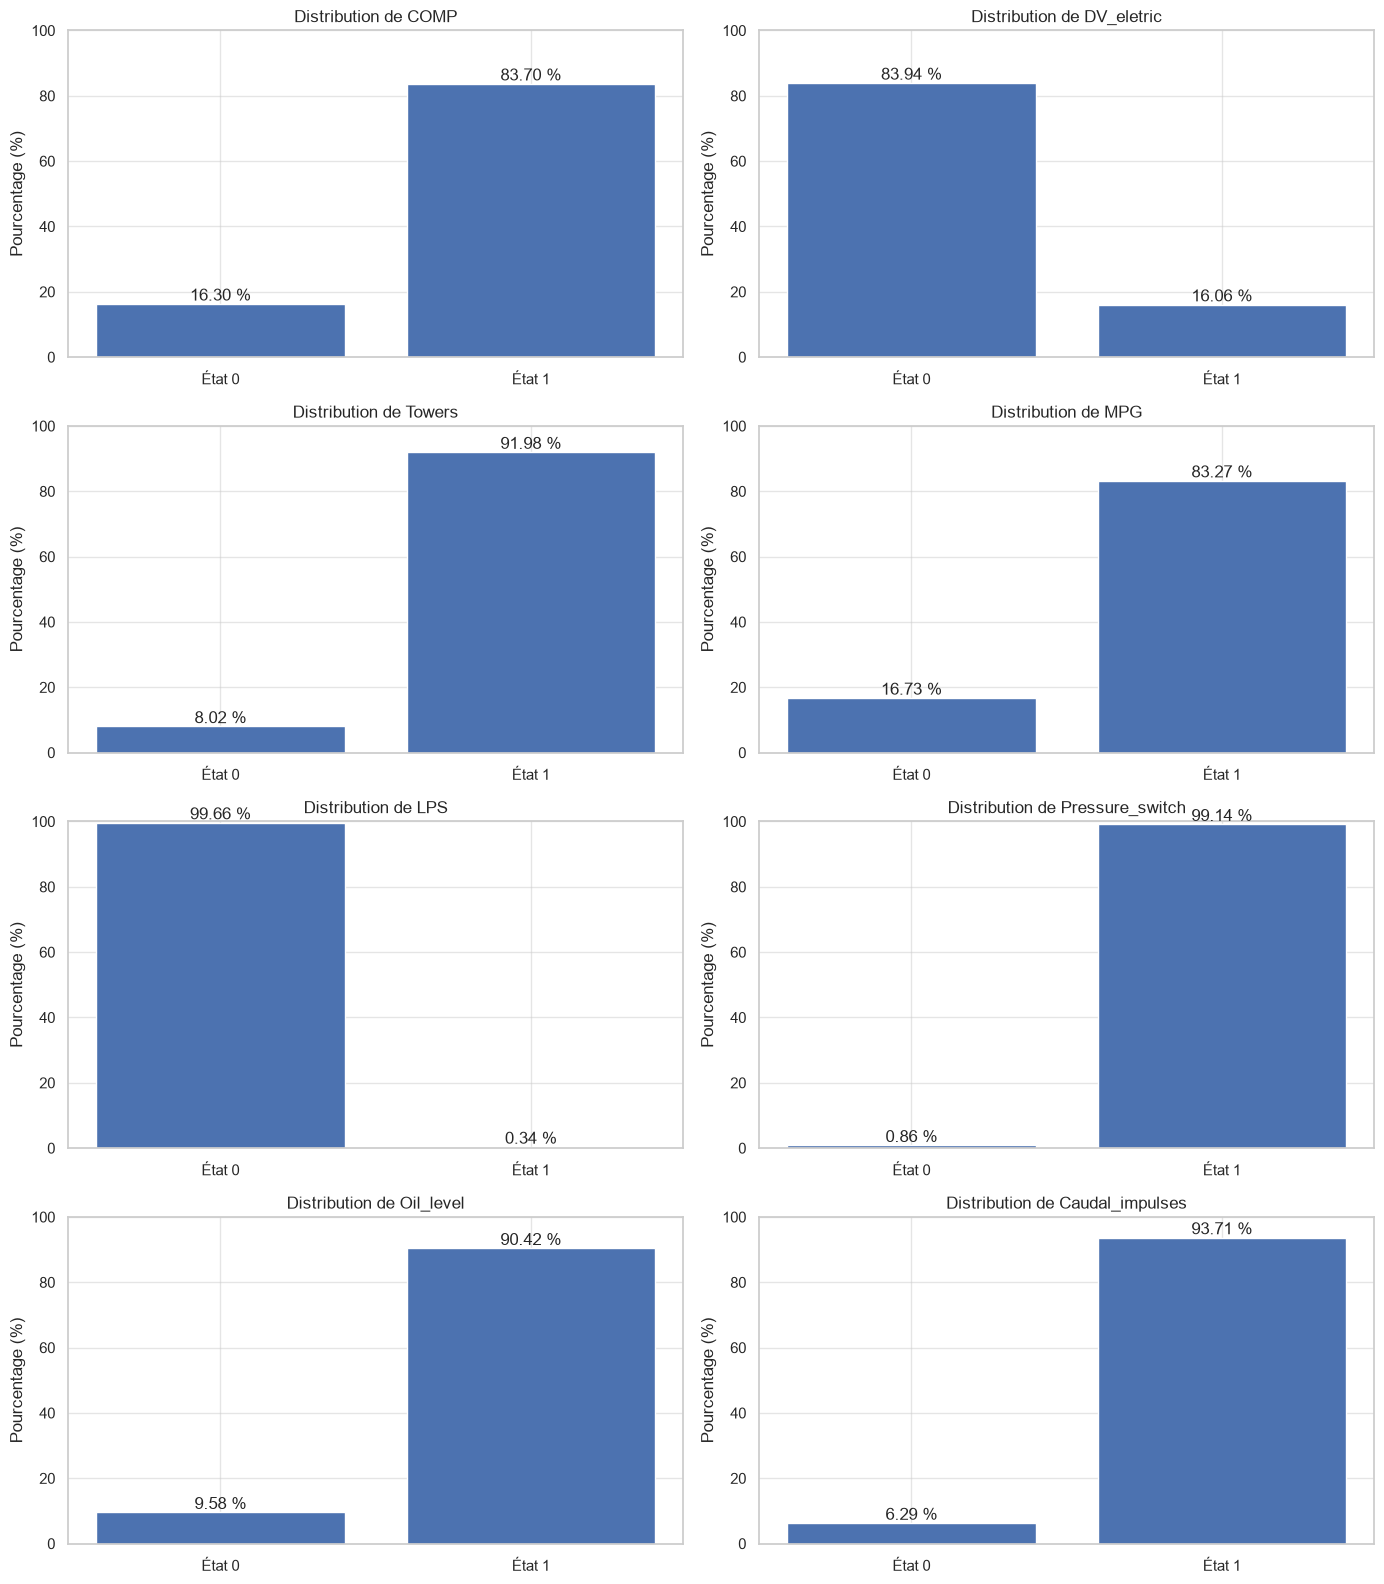

Figure enregistrée : ..\reports\figures\04_digital_variables_distribution.png


In [16]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(14, 16)
)

axes = axes.flatten()

for i, variable in enumerate(variables_digitales):

    frequences = (
        df[variable]
        .value_counts(normalize=True)
        .reindex([0.0, 1.0], fill_value=0) * 100
    )

    axes[i].bar(
        ["État 0", "État 1"],
        frequences.values
    )

    axes[i].set_title(f"Distribution de {variable}")
    axes[i].set_ylabel("Pourcentage (%)")
    axes[i].set_ylim(0, 100)

    for j, valeur in enumerate(frequences.values):
        axes[i].text(
            j,
            valeur + 1,
            f"{valeur:.2f} %",
            ha="center"
        )

plt.tight_layout()

# Sauvegarde
chemin_figure = DOSSIER_FIGURES / "04_digital_variables_distribution.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

### Interprétation des variables digitales

L'analyse des huit variables digitales confirme qu'elles sont toutes binaires et codées avec les valeurs 0 et 1.

Les fréquences observées révèlent de très différentes distributions selon les capteurs.

COMP, MPG, Towers, Pressure_switch, Oil_level et Caudal_impulses présentent une forte proportion de l'état 1. À l'inverse, DV_eletric et LPS présentent une majorité de l'état 0.

L'interprétation fonctionnelle des capteurs permet de mieux comprendre ces distributions et leur rôle dans le fonctionnement du compresseur.

Plusieurs points nécessitent toutefois une investigation complémentaire :

- La cohérence temporelle entre COMP et MPG.
- La relation entre LPS et les variables de pression.
- La fréquence élevée d'activation de Oil_level.
- Le comportement impulsionnel de Caudal_impulses.

Ces résultats constituent une première description statistique des signaux. Ils ne permettent pas, à eux seuls, de conclure sur l'état de santé du compresseur.

##  Synthèse des observations

L'analyse univariée du dataset MetroPT-3 a permis d'étudier les caractéristiques statistiques et les distributions des 15 variables explicatives.

### Variables numériques

L'étude des sept variables analogiques a révélé des comportements statistiques différents.

- TP2 présente une forte asymétrie positive et une concentration importante des valeurs près de zéro.
- TP3 et Reservoirs présentent des distributions relativement concentrées autour de 9 bar.
- H1 présente une asymétrie négative importante.
- DV_pressure présente une asymétrie positive et une kurtosis très élevées.
- Oil_temperature présente une distribution globalement symétrique.
- Motor_current présente plusieurs concentrations distinctes correspondant potentiellement à différents régimes de fonctionnement.

Les histogrammes et les boxplots ont permis de visualiser ces caractéristiques.

###  Valeurs atypiques

L'application de la règle de Tukey (1,5 × IQR) a identifié des proportions variables de valeurs atypiques :

- TP2 : 17,77 %.
- H1 : 15,91 %.
- DV_pressure : 7,46 %.
- TP3 : 0,30 %.
- Reservoirs : 0,30 %.
- Oil_temperature : 0,34 %.
- Motor_current : 0 %.

Ces observations ne sont pas automatiquement considérées comme des erreurs ou des anomalies industrielles. Aucune suppression n'a été effectuée.

### Variables digitales

Les huit variables digitales ont été vérifiées. Elles prennent toutes les valeurs 0 et 1.

Leurs fréquences montrent des distributions parfois très déséquilibrées.

Certaines variables présentent un état largement dominant, notamment LPS (99,66 % à l'état 0) et Pressure_switch (99,14 % à l'état 1).

La documentation fonctionnelle a permis d'associer les états observés à leurs fonctions dans le système de compression et de séchage de l'air.

###  Points de vigilance

Plusieurs éléments devront être approfondis dans les prochaines analyses :

- Les relations entre TP3 et Reservoirs.
- La cohérence entre COMP et MPG.
- Les relations entre LPS et les pressions mesurées.
- Les relations entre Oil_level et Oil_temperature.
- Les différents régimes de fonctionnement représentés par Motor_current.
- Le comportement temporel de Caudal_impulses.

Ces points seront étudiés dans les notebooks consacrés aux analyses bivariées, multivariées et temporelles.

##  Conclusion

L'analyse univariée a permis de caractériser les 15 variables explicatives du dataset MetroPT-3.

Les sept variables analogiques présentent des distributions hétérogènes, avec des niveaux de dispersion, d'asymétrie et de kurtosis différents.

Les histogrammes et les boxplots ont notamment mis en évidence des concentrations importantes autour de certaines valeurs ainsi que des observations statistiquement atypiques.

L'analyse des huit variables digitales a confirmé leur caractère binaire et permis de comprendre leurs fréquences à partir de la documentation fonctionnelle des capteurs.

Les résultats montrent que les variables ne présentent pas toutes les mêmes caractéristiques statistiques. Il sera donc nécessaire de tenir compte de leur nature et de leur comportement lors des futures étapes de préparation des données et de modélisation.

Aucune observation n'a été supprimée et aucune transformation n'a été appliquée durant cette étape.

**Le Notebook 04 est terminé.**

La prochaine étape consistera à étudier les relations entre les variables afin d'identifier les dépendances, les corrélations, les redondances et les relations potentielles avec la variable cible.